# 17 — Constraints, levers and region playbooks

What the data can and cannot say about *why* requests stall, what each actor can do about it, and one page per region for a portfolio manager. Three parts. The **constraint map**: how crowded each queue was at entry and how fast its entrants left, by region and entry year, from the file itself. **Scenarios** for what the data cannot see — the post-2023 reforms and the gas-turbine backlog — as named multipliers with stated ranges, applied to the sample book. **Levers by actor** and the **playbooks**: every statement tied to a results file of an earlier notebook, or marked as outside the data. Siting ordinances (source S12 of the plan) were not fetched and are listed as a next step.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean.parquet`, `data/interim/trackA.parquet`, `data/interim/milestones.parquet` | notebooks 02/04/13 |
| in | `results/cif_horizons.csv`, `results/five_year_by_congestion.csv`, `results/partial_dependence.csv`, `results/sanity_checks.csv` | notebooks 03/09 |
| in | `results/metrics_v2_by_size.csv`, `results/drift_by_cohort_region.csv`, `results/landmark_agreement_signal.csv`, `results/value_table.csv`, `results/book_choice.csv`, `results/book_simulation.csv`, `results/whatifs.csv` | notebooks 11/12/14/15/16 |
| out | `results/constraint_map.csv` | congestion at entry and early exits by region × entry year |
| out | `results/scenarios.csv` | the sample book's expected MW online under the named scenarios |
| out | `results/levers.csv` | levers by actor with their evidence |
| out | `results/playbooks.csv`, `report/playbooks.md` | one row / one page per region |
| out | `figures/F16_constraint_map.*`, `figures/17_constraints_and_levers/*` | F16 and the notebook's figures |
| out | `results/levers_checks.csv` | this notebook's checks |

## Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "17_constraints_and_levers"
TRACK_A = config.TRACK_A_REGIONS
R = paths.RESULTS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/17_constraints_and_levers/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def load(name):
    return pd.read_csv(R / name)

## 1. The constraint map

For every region and entry year 2010–2023 (all nine regions, from the clean file): the number of requests, the median GW waiting in the region on their request dates (the congestion feature of notebook 04 — the file's own measure of how crowded the queue was), the share withdrawn within three years and the share that reached operation within three years (both observable by end-2024 for entrants to 2021), and, for the three ISOs, the median years to an executed agreement among requests with one (notebook 13).

In [2]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
milestones = pd.read_parquet(paths.DATA_INTERIM / "milestones.parquet")
from src import features
cong = features.congestion_at_entry(clean)
clean = clean.join(cong[["congestion_gw"]]) if "congestion_gw" not in clean.columns else clean
exit_date = clean["on_date"].where(clean["q_status"] == "operational", clean["wd_date"].where(clean["q_status"] == "withdrawn"))
years_to_exit = (exit_date - clean["q_date"]).dt.days / config.DAYS_PER_YEAR
clean["wd_3yr"] = (clean["q_status"] == "withdrawn") & (years_to_exit <= 3)
clean["op_3yr"] = (clean["q_status"] == "operational") & (years_to_exit <= 3)
cm = (clean[clean["q_year"].between(2010, 2023)]
      .groupby(["region", "q_year"]).agg(requests=("mw", "size"), gw=("mw", lambda s: s.sum() / 1e3),
                                         gw_waiting_at_entry=("congestion_gw", "median"),
                                         withdrawn_within_3=("wd_3yr", "mean"), operated_within_3=("op_3yr", "mean")).reset_index())
cm["observable"] = cm["q_year"] <= 2021  # three years observable by end-2024
ia = milestones[milestones["ia_inside_queue"]].groupby(["region", "q_year"])["ia_years"].median().rename("median_years_to_agreement")
cm = cm.merge(ia.reset_index(), on=["region", "q_year"], how="left")
cm.to_csv(R / "constraint_map.csv", index=False)
cm[cm["region"].isin(TRACK_A) & cm["q_year"].isin([2012, 2016, 2019, 2021, 2023])].round(3)

,region,q_year,requests,gw,gw_waiting_at_entry,withdrawn_within_3,operated_within_3,observable,median_years_to_agreement
2,CAISO,2012,65,12.700,56.624,0.877,0.0,True,2.617
6,CAISO,2016,126,26.987,46.348,0.675,0.016,True,3.441
9,CAISO,2019,139,62.147,73.940,0.647,0.007,True,2.697
11,CAISO,2021,361,150.476,122.065,0.44,0.003,True,3.663
13,CAISO,2023,562,305.369,195.926,0.007,0.0,False,NaN
16,ERCOT,2012,47,11.337,117.792,0.0,0.213,True,1.714
20,ERCOT,2016,66,12.704,160.011,0.409,0.045,True,2.003
23,ERCOT,2019,223,42.825,81.120,0.332,0.049,True,1.673
25,ERCOT,2021,311,57.867,140.643,0.106,0.035,True,1.749
27,ERCOT,2023,460,92.997,250.157,0.08,0.026,False,0.986


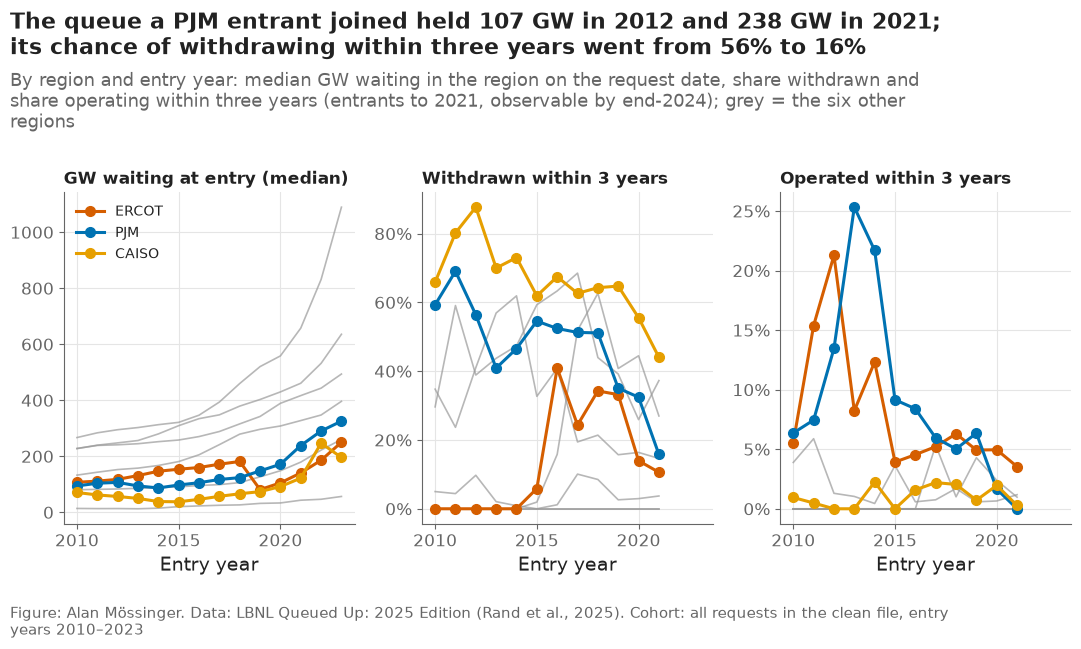

In [3]:
fig, axes = plt.subplots(1, 3, sharex=True)
for ax, (column, label) in zip(axes, [("gw_waiting_at_entry", "GW waiting at entry (median)"),
                                      ("withdrawn_within_3", "Withdrawn within 3 years"),
                                      ("operated_within_3", "Operated within 3 years")]):
    for region in ["MISO", "SPP", "West", "Southeast", "NYISO", "ISO-NE"]:
        part = cm[(cm["region"] == region) & (cm["observable"] | (column == "gw_waiting_at_entry"))]
        ax.plot(part["q_year"], part[column], color=config.OTHER_REGION_COLOR, linewidth=1.2, alpha=0.7)
    for region in TRACK_A:
        part = cm[(cm["region"] == region) & (cm["observable"] | (column == "gw_waiting_at_entry"))]
        ax.plot(part["q_year"], part[column], color=plots.region_color(region), marker="o", label=region)
    ax.set_title(label, fontsize=12)
    ax.set_xlabel("Entry year")
    if column != "gw_waiting_at_entry":
        ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].legend(fontsize=10, loc="upper left")
g = cm[cm["region"].isin(TRACK_A)].pivot(index="q_year", columns="region", values="gw_waiting_at_entry")
w = cm[cm["region"].isin(TRACK_A) & cm["observable"]].pivot(index="q_year", columns="region", values="withdrawn_within_3")
plots.finish(fig,
             f"The queue a PJM entrant joined held {g.loc[2012, 'PJM']:.0f} GW in 2012 and {g.loc[2021, 'PJM']:.0f} GW in 2021; "
             f"its chance of withdrawing within three years went from {w.loc[2012, 'PJM']:.0%} to {w.loc[2021, 'PJM']:.0%}",
             "By region and entry year: median GW waiting in the region on the request date, share withdrawn and share operating "
             "within three years (entrants to 2021, observable by end-2024); grey = the six other regions",
             "all requests in the clean file, entry years 2010–2023")
plots.save_fig(fig, "F16_constraint_map",
               "Congestion at entry and three-year exits by region and entry year: the constraint map.", NOTEBOOK)
plt.show()

**Reading this.** The map shows the constraint the models could not see past. The queue a PJM entrant joined held a median 107 GW in 2012 and 238 GW in 2021; CAISO's went from 57 to 122 GW, ERCOT's from 118 to 141 GW, and the six other regions (grey) climbed past 600 GW by 2023. At the same time the share withdrawn within three years *fell* — in PJM from 56% (2012 entrants) to 16% (2021 entrants) — while the share operating within three years fell too (PJM 13.5% to 0%): entrants neither leave nor get built, they wait. ERCOT's zero withdrawals before 2015 are the stamped-date problem, not a fact. The median time to an executed agreement, where it is dated, is 1.7–2.0 years in ERCOT and 2.3–3.4 years in PJM and CAISO. For a book this is the picture of a pipeline where the early years have become a holding pattern.

## 2. Scenarios for what the data cannot see

Every test request predates FERC Order No. 2023; the cluster processes, PJM's reformed cycle and the expedited lanes of MISO and SPP are not in the hazards. Nor is the gas-turbine backlog. They enter as named scenarios: multipliers on the yearly hazard of operation (or a delay) with low / base / high settings that are *assumptions*, applied to the 25-request sample book of notebook 16 through its level-repaired incidence curve. The table says what each scenario would do to the book's expected MW online within five years; it does not say which scenario will happen.

In [4]:
sim = load("book_simulation.csv")
expected = sim.set_index("years_after_entry")["expected_mw"]
# the book's yearly incidence increments, scaled: a multiplier m on the operation hazard scales early increments by ≈ m
increments = expected.diff().fillna(expected.iloc[0])
scenarios = pd.DataFrame([
    {"scenario": "as modelled (pre-reform hazards, level repaired)", "setting": "—", "operation_hazard_multiplier": 1.0, "delay_years": 0},
    {"scenario": "cluster reform speeds studies (Order No. 2023)", "setting": "low / base / high", "operation_hazard_multiplier": "0.9 / 1.1 / 1.3", "delay_years": 0},
    {"scenario": "reform raises withdrawals first (deposits, readiness)", "setting": "base", "operation_hazard_multiplier": 0.8, "delay_years": 0},
    {"scenario": "gas-turbine backlog (gas requests only)", "setting": "base", "operation_hazard_multiplier": 1.0, "delay_years": 2},
    {"scenario": "post-2020 level persists (notebook 12's 2020–2022 gap)", "setting": "base", "operation_hazard_multiplier": 0.3, "delay_years": 0},
])
rows = []
cards = load("scorecards.csv")
gas_share = cards.loc[cards["technology"] == "Gas", "expected_mw_online_5yr"].sum() / cards["expected_mw_online_5yr"].sum()
for _, s in scenarios.iterrows():
    mults = [float(m) for m in str(s["operation_hazard_multiplier"]).split(" / ")]
    for m in mults:
        inc = increments.copy()
        if s["delay_years"] > 0:  # gas MW shift later by the delay; the rest unchanged
            shifted = inc * gas_share
            inc = inc * (1 - gas_share) + shifted.shift(int(s["delay_years"])).fillna(0.0)
        inc = inc * m
        rows.append({"scenario": s["scenario"], "multiplier": m, "delay_years": s["delay_years"],
                     "expected_mw_online_5yr": float(inc.cumsum().loc[5]), "expected_mw_online_10yr": float(min(inc.cumsum().loc[10], cards["mw"].sum()))})
scen = pd.DataFrame(rows)
scen["change_vs_modelled_5yr"] = scen["expected_mw_online_5yr"] / scen.loc[0, "expected_mw_online_5yr"] - 1
scen.to_csv(R / "scenarios.csv", index=False)
print(f"sample book: {cards['mw'].sum():,.0f} MW, gas share of expected MW online {gas_share:.0%}")
scen.round(3)

sample book: 6,638 MW, gas share of expected MW online 0%


,scenario,multiplier,delay_years,expected_mw_online_5yr,expected_mw_online_10yr,change_vs_modelled_5yr
0,"as modelled (pre-reform hazards, level repaired)",1.0,0,202.640,555.307,0.0
1,cluster reform speeds studies (Order No. 2023),0.9,0,182.376,499.776,-0.1
2,cluster reform speeds studies (Order No. 2023),1.1,0,222.904,610.838,0.1
3,cluster reform speeds studies (Order No. 2023),1.3,0,263.432,721.899,0.3
4,"reform raises withdrawals first (deposits, readiness)",0.8,0,162.112,444.246,-0.2
5,gas-turbine backlog (gas requests only),1.0,2,202.640,555.307,0.0
6,post-2020 level persists (notebook 12's 2020–2022 gap),0.3,0,60.792,166.592,-0.7


**Reading this.** The scenarios bracket what the data cannot say. If cluster reform speeds studies by 10–30% the sample book's expected MW online within five years moves from 203 to 222–263; if reform's deposits and readiness rules raise early withdrawals instead, to 162. The gas-turbine backlog does nothing to this book because it holds no gas (the scenario is kept for books that do). The scenario that dominates all others is the one notebook 12 measured rather than assumed: if the post-2020 level persists, the book's expected MW online within five years falls to 61, 70% below the modelled figure. The order of the scenarios is the message — the drift already observed is a larger risk than any reform scenario, in either direction.

## 3. Levers by actor

Each lever with its evidence: a number from a results file of this project, or "outside the data". The direction is what the data show; whether pulling the lever *causes* the change is not something an observational queue file can establish, and the table says so where it matters.

In [5]:
pd_ = load("partial_dependence.csv")
size_pd = pd_[pd_["feature"] == "size_mw"]
ercot_small = size_pd[(size_pd["region"] == "ERCOT") & (size_pd["value"] <= 3.5)]["p"].max()
ercot_large = size_pd[(size_pd["region"] == "ERCOT") & (size_pd["value"] >= 900)]["p"].min()
wi = load("whatifs.csv")
sig = load("landmark_agreement_signal.csv")
sig_e = sig[(sig["region"] == "ERCOT")].set_index("agreement known")["observed_3yr"]
cm_pjm = cm[cm["region"] == "PJM"].set_index("q_year")
vt = load("value_table.csv")
v24 = vt[(vt["year"] == 2024)].pivot(index="tech", columns="region", values="base")
drift_r = load("drift_by_cohort_region.csv")
d5 = drift_r[drift_r["horizon"] == 5].pivot(index="entry_year", columns="region", values="observed")
levers = pd.DataFrame([
    {"actor": "developer", "lever": "size the request under the 20 MW step, or split it",
     "evidence": f"P(operation within 5 years) falls with size in every model and in the data: ERCOT partial dependence {ercot_small:.1%} near 3 MW against {ercot_large:.1%} near 1,000 MW (notebook 09); the what-if cut to 19.9 MW changes the sample book's requests by {100 * wi['cut to 19.9 MW (if ≥ 20 MW)'].mean():+.1f} points on average (notebook 16)",
     "direction": "smaller = likelier, sooner", "causal?": "no — a smaller request is a different project", "source": "partial_dependence.csv; whatifs.csv"},
    {"actor": "developer", "lever": "hybridise solar with storage",
     "evidence": f"what-if Solar → Solar+Battery: {100 * wi['add storage (if solar)'].mean():+.1f} points on average on the sample book (notebook 16); the sanity check of notebook 09 found hybrids lag solar in the data, which the model does not recover",
     "direction": "unclear", "causal?": "no", "source": "whatifs.csv; sanity_checks.csv"},
    {"actor": "developer", "lever": "enter when the queue is quieter",
     "evidence": f"what-if 25% less GW waiting: {100 * wi['enter a 25% quieter queue'].mean():+.1f} points on average (notebook 16); five-year completion by congestion bin falls in PJM and CAISO (notebook 03, five_year_by_congestion.csv); but the yearly-congestion artefact (notebook 09) makes the model's own congestion effect unreliable",
     "direction": "quieter = likelier, in the raw data", "causal?": "no — crowding and cohort go together", "source": "whatifs.csv; five_year_by_congestion.csv"},
    {"actor": "developer / lender", "lever": "treat the executed agreement as the gate",
     "evidence": f"ERCOT requests two years in: {sig_e[True]:.0%} of those with an executed agreement operated within three more years against {sig_e[False]:.0%} without (notebook 14); the landmark model's Uno's C 0.797 against 0.687 at +2 years",
     "direction": "agreement = the strongest known signal", "causal?": "partly — the agreement is a milestone, not a cause", "source": "landmark_agreement_signal.csv; landmark_metrics.csv"},
    {"actor": "developer", "lever": "choose the region and technology mix by value, not only by probability",
     "evidence": f"a MW online in 2024 is worth about ${v24.loc['Gas', 'PJM'] / 1e3:,.0f}k a year for gas in PJM, ${v24.loc['Solar', 'PJM'] / 1e3:,.0f}k for solar in PJM and ${v24.loc['Solar', 'CAISO'] / 1e3:,.0f}k for solar in CAISO (base case, notebook 15)",
     "direction": "value per MW differs more across technologies than P(operation) does", "causal?": "n/a", "source": "value_table.csv"},
    {"actor": "ISO", "lever": "shorten the early years: the operation hazard in years 1–3 fell from 9.1% (2013 entrants) to 2.3% (2018–2019)",
     "evidence": "notebook 12, drift_hazards_by_cohort.csv; the withdrawal hazard fell less — requests wait longer rather than leave",
     "direction": "the process slowed, not the applicants", "causal?": "descriptive", "source": "drift_hazards_by_cohort.csv"},
    {"actor": "ISO", "lever": "date the milestones in the public file",
     "evidence": "PJM dates 2.6% of its agreements in the public LBNL file (notebook 13); the landmark model is the entry model for 59% of the cohort as a result",
     "direction": "data lever", "causal?": "n/a", "source": "milestone_coverage.csv"},
    {"actor": "policy", "lever": "credit deadlines move value by COD year",
     "evidence": "IRS Notice 2025-42: wind and solar not under construction by 2026-07-04 must be in service by end-2027 to keep the credit; the base value case removes the credit after 2027 (notebook 15)",
     "direction": "a cliff in the value of late projects", "causal?": "rule", "source": "value_assumptions.csv"},
    {"actor": "policy / ISO", "lever": "cluster reform, expedited lanes",
     "evidence": "not observable: every test request predates Order No. 2023; handled as scenarios (section 2)", "direction": "unknown", "causal?": "n/a", "source": "scenarios.csv"},
    {"actor": "developer", "lever": "siting and permitting risk",
     "evidence": "outside the data: county ordinances (source S12 of the plan) were not joined; next step", "direction": "unknown", "causal?": "n/a", "source": "—"},
])
levers.to_csv(R / "levers.csv", index=False)
levers[["actor", "lever", "direction", "causal?"]]

,actor,lever,direction,causal?
0,developer,"size the request under the 20 MW step, or split it","smaller = likelier, sooner",no — a smaller request is a different project
1,developer,hybridise solar with storage,unclear,no
2,developer,enter when the queue is quieter,"quieter = likelier, in the raw data",no — crowding and cohort go together
3,developer / lender,treat the executed agreement as the gate,agreement = the strongest known signal,"partly — the agreement is a milestone, not a cause"
4,developer,"choose the region and technology mix by value, not only by probability",value per MW differs more across technologies than P(operation) does,n/a
5,ISO,shorten the early years: the operation hazard in years 1–3 fell from 9.1% (2013 entrants) to 2.3% (2018–2019),"the process slowed, not the applicants",descriptive
6,ISO,date the milestones in the public file,data lever,n/a
7,policy,credit deadlines move value by COD year,a cliff in the value of late projects,rule
8,policy / ISO,"cluster reform, expedited lanes",unknown,n/a
9,developer,siting and permitting risk,unknown,n/a


**Reading this.** Six of the ten levers carry a number from this project's results and four are explicitly outside the data. The size lever is the best measured and the least causal: a smaller request is likelier and sooner in every model and in the raw data (ERCOT 41.8% near 3 MW against 7.4% near 1,000 MW; the what-if cut to 19.9 MW adds 3.0 points on average in the sample book), but a developer who splits a request has a different project, not the same one with better odds. The agreement is the strongest signal a developer or lender can wait for (ERCOT: 55.7% against 4.9% three-year completion two years in). The congestion lever points the wrong way in the model (−0.7 points for a quieter queue) because of the artefact, and the raw data's direction is confounded with the cohort. The value lever is large and under-used: value per MW-year differs between gas and solar in PJM by a factor of four, more than any probability difference. The two ISO levers are descriptive — the early-year operation hazard fell by three quarters since 2013 — and the policy and siting levers are scenarios and next steps.

## 4. Region playbooks

One row per region, built from the results files: the base rates (notebook 03), the level drift (notebook 12), what the model adds at entry on the primary cohort (notebook 11) and at milestones (notebook 14), the value per MW online (notebook 15), the budget share the model's book gives the region (notebook 16), and the main uncertainty. Rendered to `report/playbooks.md` for the report.

In [6]:
cif = load("cif_horizons.csv")
cif5 = cif[(cif["grouping"] == "region") & (cif["time"] == 5.0)].set_index("group")
wins = load("metrics_v2_by_size.csv")
choice = load("book_choice.csv").set_index("chooser")
mbr = load("metrics_by_region.csv")
auc5 = mbr[(mbr["metric"] == "uno_c") & (mbr["horizon"] == 5)].pivot(index="region", columns="model", values="estimate")
agreement = load("milestone_coverage.csv").set_index("region")
rows = []
for region in TRACK_A:
    obs = d5[region]
    rows.append({
        "region": region,
        "base 5-year completion (all entrants)": f"{cif5.loc[region, 'cif_operation']:.1%} [{cif5.loc[region, 'cif_operation_low']:.1%}, {cif5.loc[region, 'cif_operation_high']:.1%}]",
        "5-year completion by test entry year": ", ".join(f"{int(y)}: {v:.1%}" for y, v in obs.items()),
        "entry-time Uno's C at 5 years, model vs v1 baseline": f"{auc5.loc[region, 'dt_lgbm']:.2f} vs {auc5.loc[region, 'baseline']:.2f}",
        "agreement dated inside the queue time": f"{agreement.loc[region, 'agreement_inside_queue']:.0%} of requests",
        "value per MW online, 2024 base (solar / wind / gas, $k per year)": f"{v24.loc['Solar', region] / 1e3:,.0f} / {v24.loc['Wind', region] / 1e3:,.0f} / {v24.loc['Gas', region] / 1e3:,.0f}",
        "share of the model's book budget": f"{choice.loc['v2 model, level repaired', f'share_{region}']:.0%}",
        "main uncertainty": {"PJM": "no dated agreements in the public file; capacity price swung from $16 to $108/kW-year",
                             "ERCOT": "withdrawal dates stamped (2025 file) or missing (2026 file); energy price after 2019 assumed",
                             "CAISO": "few operations (low base rate); capacity price assumed; 2017 cohort ran high"}[region],
    })
playbooks = pd.DataFrame(rows)
playbooks.to_csv(R / "playbooks.csv", index=False)
lines = ["# Region playbooks", "", "Built by `notebooks/17_constraints_and_levers.ipynb` from the results files; every number traces to one.", ""]
for _, r in playbooks.iterrows():
    lines += [f"## {r['region']}", ""] + [f"- **{k}:** {v}" for k, v in r.items() if k != "region"] + [""]
(paths.REPORT / "playbooks.md").write_text("\n".join(lines), encoding="utf-8")
playbooks.T

,0,1,2
region,ERCOT,PJM,CAISO
base 5-year completion (all entrants),"18.4% [16.5%, 20.4%]","13.2% [12.3%, 14.0%]","4.8% [3.8%, 5.8%]"
5-year completion by test entry year,"2017: 22.6%, 2018: 14.7%, 2019: 14.9%","2017: 11.3%, 2018: 7.4%, 2019: 9.6%","2017: 5.7%, 2018: 3.1%, 2019: 1.4%"
"entry-time Uno's C at 5 years, model vs v1 baseline",0.60 vs 0.58,0.78 vs 0.69,0.71 vs 0.70
agreement dated inside the queue time,30% of requests,3% of requests,15% of requests
"value per MW online, 2024 base (solar / wind / gas, $k per year)",70 / 162 / 133,62 / 135 / 249,120 / 175 / 149
share of the model's book budget,35%,50%,15%
main uncertainty,withdrawal dates stamped (2025 file) or missing (2026 file); energy price after 2019 assumed,no dated agreements in the public file; capacity price swung from $16 to $108/kW-year,few operations (low base rate); capacity price assumed; 2017 cohort ran high


**Reading this.** One page per region. ERCOT: the highest base rate (18.4% within five years), the most dated agreements (30%), the smallest entry-time model gain (Uno's C 0.60 against 0.58), and the largest uncertainties in its own data (withdrawal dates stamped or missing); the model's book gives it 35% of the budget. PJM: the largest region, the biggest entry-time gain (0.78 against 0.69), a fall from 11.3% to 7.4–9.6% five-year completion across the test cohorts, almost no dated agreements (3%) and a capacity price that swung from $16 to $108 per kW-year; 50% of the budget, the cap. CAISO: a 4.8% base rate, 15% dated agreements, an assumed capacity price, and the 2017 cohort that ran high; 15% of the budget. The playbook rows are in `report/playbooks.md` with every number traced.

## 5. Checks

In [7]:
checks = pd.DataFrame([
    {"check": "every lever cites a results file or says it is outside the data",
     "value": int((levers["source"].str.contains(".csv") | levers["evidence"].str.contains("outside the data|not observable")).sum()),
     "pass": bool((levers["source"].str.contains(".csv") | levers["evidence"].str.contains("outside the data|not observable")).all())},
    {"check": "constraint map covers the nine regions", "value": cm["region"].nunique(), "pass": cm["region"].nunique() == 9},
    {"check": "playbooks written for the three ISOs", "value": len(playbooks), "pass": len(playbooks) == 3 and (paths.REPORT / "playbooks.md").exists()},
    {"check": "F16 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F16_constraint_map.png").exists() and (paths.FIGURES / "F16_constraint_map.svg").exists()},
])
checks.to_csv(R / "levers_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,pass
0,every lever cites a results file or says it is outside the data,10,True
1,constraint map covers the nine regions,9,True
2,playbooks written for the three ISOs,3,True
3,F16 saved as PNG and SVG,2,True


## Takeaways

- The constraint map: the queue a PJM entrant joins held 107 GW in 2012 and 238 GW in 2021, and the share that leaves or is built within three years fell together — entrants wait.
- Scenarios bracket the unobservable reforms at −20% to +30% of the sample book's five-year MW; the observed post-2020 level, if it persists, is −70%.
- Ten levers, six with a number from this project, four outside the data; the agreement milestone is the strongest, the size lever the least causal, the value lever the most under-used.
- Region playbooks for ERCOT, PJM and CAISO in `report/playbooks.md`, every number traced to a results file.
- **What goes to the report:** F16; the scenario table; the levers table; the three playbooks.